# RUL Estimation — CNC Machining Centre (v3-fast, Colab-ready)

Leakage-corrected pipeline with a fair, budget-matched comparison of Decision Tree, Random Forest,
Gradient Boosting, LSTM and CNN-LSTM.

**Run in Colab:** Runtime → Change runtime type → **T4 GPU** → upload the CSV → Runtime → Run all.

**Speed settings** (top of Section 1):
- `FAST = True` (default): light Optuna search (8 trials), 3 final seeds. Roughly 20–30 min on a T4.
- `FAST = False`: full search (25 trials), 5 seeds. Expect 60–90 min.
- `RUN_TUNING = False`: skips the search and uses the stored parameters. Roughly 8–10 min.

Results are whatever the held-out machines produce; no target is forced.

In [8]:
# ---- Settings ----
FAST = True            # False = full search (slower, more trials/seeds)
RUN_TUNING = True      # False = use stored best parameters (fastest)
N_TRIALS = 8 if FAST else 25
TUNE_EPOCHS = 15 if FAST else 25
FINAL_EPOCHS = 40 if FAST else 80
SEEDS = [42, 43, 44] if FAST else [42, 43, 44, 45, 46]
DATA_PATH = "cnc_machining_centre_rul_dataset__2_.csv"

%pip install -q optuna
import os, json, random, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Sequential
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import optuna

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")
SEED = 42
def set_seed(s):
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)
set_seed(SEED)
print("TensorFlow", tf.__version__, "| GPU:", bool(tf.config.list_physical_devices("GPU")))
T0 = time.time()

TensorFlow 2.21.0 | GPU: True


## 2. Load, Dedupe, Column Roles

In [9]:
try:
    from google.colab import files
    if not os.path.exists(DATA_PATH):
        DATA_PATH = list(files.upload())[0]
except ImportError:
    pass

df = pd.read_csv(DATA_PATH).drop_duplicates().sort_values(["unit_id", "cycle"]).reset_index(drop=True)
print("Rows:", len(df), "| machines:", df.unit_id.nunique())

ID_COLS = ["unit_id", "cycle", "timestamp", "shift", "machine_type"]
TARGET = "RUL"
LEAKAGE_COLS = ["RUL", "label_binary_30", "label_binary_15", "health_state", "failure_mode"]
DISTRACTORS = ["ambient_light_lux", "power_grid_voltage_V"]
SENSOR_COLS = [c for c in df.columns if c not in ID_COLS + LEAKAGE_COLS + DISTRACTORS]
assert not set(SENSOR_COLS) & set(LEAKAGE_COLS)
print(len(SENSOR_COLS), "sensor features")

Saving cnc_machining_centre_rul_dataset (2).csv to cnc_machining_centre_rul_dataset (2).csv
Rows: 43706 | machines: 100
26 sensor features


## 3. Split by Machine, Clean (training statistics only), Engineer Causal Features

In [10]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, te_idx = next(gss.split(df, groups=df["unit_id"]))
train = df.iloc[tr_idx].copy(); test = df.iloc[te_idx].copy()
assert set(train.unit_id).isdisjoint(test.unit_id)

def ffill_machine(part):
    part = part.copy()
    part[SENSOR_COLS] = part.groupby("unit_id")[SENSOR_COLS].transform(lambda s: s.ffill())
    return part
train, test = ffill_machine(train), ffill_machine(test)

med = train[SENSOR_COLS].median()
q1, q3 = train[SENSOR_COLS].quantile(0.25), train[SENSOR_COLS].quantile(0.75)
lo, hi = q1 - 3 * (q3 - q1), q3 + 3 * (q3 - q1)
for p in (train, test):
    p[SENSOR_COLS] = p[SENSOR_COLS].fillna(med).clip(lower=lo, upper=hi, axis=1)

KEY = [c for c in ["spindle_vibration_x_mm_s", "spindle_vibration_y_mm_s", "spindle_vibration_z_mm_s",
                   "bearing_temperature_C", "motor_current_A", "spindle_torque_Nm", "tool_wear_mm",
                   "acoustic_emission_dB", "cutting_force_N", "power_consumption_kW"] if c in SENSOR_COLS]

def add_features(part):
    g = part.groupby("unit_id"); new = {}
    for c in KEY:
        new[f"{c}_mean5"] = g[c].transform(lambda s: s.rolling(5, min_periods=1).mean())
        new[f"{c}_std5"] = g[c].transform(lambda s: s.rolling(5, min_periods=2).std().fillna(0))
        new[f"{c}_mean15"] = g[c].transform(lambda s: s.rolling(15, min_periods=1).mean())
        new[f"{c}_diff1"] = g[c].diff().fillna(0)
        new[f"{c}_ewm10"] = g[c].transform(lambda s: s.ewm(span=10, adjust=False).mean())
    return pd.concat([part, pd.DataFrame(new, index=part.index)], axis=1)

train, test = add_features(train), add_features(test)
FEATURES = SENSOR_COLS + [c for c in train.columns if c not in df.columns]

scaler = StandardScaler().fit(train[FEATURES])
train[FEATURES] = scaler.transform(train[FEATURES])
test[FEATURES] = scaler.transform(test[FEATURES])
RUL_CLIP = 130
print("Features:", len(FEATURES), "| train rows:", len(train), "| test rows:", len(test))

Features: 76 | train rows: 35319 | test rows: 8387


## 4. Metrics

In [11]:
def asym_score(y, p):
    d = np.asarray(p, float) - np.asarray(y, float)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

def metrics(y, p):
    return {"RMSE": mean_squared_error(y, p) ** 0.5, "MAE": mean_absolute_error(y, p),
            "R2": r2_score(y, p), "AsymScore": asym_score(y, p)}

X_tr, y_tr = train[FEATURES].values, train[TARGET].clip(upper=RUL_CLIP).values
X_te, y_te = test[FEATURES].values, test[TARGET].clip(upper=RUL_CLIP).values

## 5. Tabular Models (Decision Tree, Random Forest, Gradient Boosting)

In [12]:
results, preds = [], {}
TAB_MODELS = {}
def run_tabular(name, make):
    m = make().fit(X_tr, y_tr)
    TAB_MODELS[name] = m
    p = m.predict(X_te)
    row = {"Model": name, **metrics(y_te, p)}
    results.append(row); preds[name] = p
    print(f"{name:>20s} | R2 {row['R2']:.3f} | RMSE {row['RMSE']:.2f} | MAE {row['MAE']:.2f}")

run_tabular("Decision Tree", lambda: DecisionTreeRegressor(max_depth=8, min_samples_leaf=15, random_state=SEED))
run_tabular("Random Forest", lambda: RandomForestRegressor(n_estimators=120, max_depth=14, min_samples_leaf=5,
                                                           n_jobs=-1, random_state=SEED))
run_tabular("Gradient Boosting", lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.06,
                                                                       random_state=SEED))

       Decision Tree | R2 0.918 | RMSE 10.54 | MAE 4.60
       Random Forest | R2 0.944 | RMSE 8.73 | MAE 3.75
   Gradient Boosting | R2 0.926 | RMSE 10.00 | MAE 4.75


## 6. Sequence Builder and Architectures

In [13]:
def make_sequences(part, window):
    X, y = [], []
    for _, g in part.groupby("unit_id", sort=False):
        F = g[FEATURES].values.astype(np.float32)
        r = g[TARGET].clip(upper=RUL_CLIP).values.astype(np.float32)
        Fp = np.vstack([np.zeros((window - 1, F.shape[1]), np.float32), F])
        for i in range(len(F)):
            X.append(Fp[i:i + window]); y.append(r[i])
    return np.stack(X), np.array(y, np.float32)

# Inner machine-level split of the TRAINING data: used for tuning and early stopping only
a, b = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED + 1).split(train, groups=train.unit_id))
inner_tr, inner_va = train.iloc[a], train.iloc[b]
_cache = {}
def inner_seq(w):
    if w not in _cache:
        _cache[w] = (*make_sequences(inner_tr, w), *make_sequences(inner_va, w))
    return _cache[w]

def build_lstm(w, nf, u1, u2, do, lr):
    m = Sequential([layers.Input((w, nf)), layers.LSTM(u1, return_sequences=True), layers.Dropout(do),
                    layers.LSTM(u2), layers.Dropout(do), layers.Dense(32, activation="relu"), layers.Dense(1)])
    m.compile(keras.optimizers.Adam(lr), loss="mse"); return m

def build_cnn_lstm(w, nf, filters, k, u1, u2, do, lr):
    m = Sequential([layers.Input((w, nf)),
                    layers.Conv1D(filters, k, padding="same", activation="relu"), layers.BatchNormalization(),
                    layers.Conv1D(filters // 2, k, padding="same", activation="relu"),
                    layers.MaxPooling1D(2, padding="same"),
                    layers.LSTM(u1, return_sequences=True), layers.Dropout(do),
                    layers.LSTM(u2), layers.Dropout(do), layers.Dense(32, activation="relu"), layers.Dense(1)])
    m.compile(keras.optimizers.Adam(lr), loss="mse"); return m

def fit_seq(make, Xa, ya, Xb, yb, epochs, batch, seed):
    set_seed(seed); m = make()
    m.fit(Xa, ya, validation_data=(Xb, yb), epochs=epochs, batch_size=batch, verbose=0,
          callbacks=[EarlyStopping("val_loss", patience=6, restore_best_weights=True),
                     ReduceLROnPlateau("val_loss", factor=0.5, patience=3, min_lr=1e-5)])
    return m

## 7. Hyperparameter Search (Optuna, budget-matched for both deep models)
Both models get the same number of trials. The search space is kept small on purpose so it finishes in
reasonable Colab time. Set `RUN_TUNING = False` in Section 1 to skip it and use the stored parameters.

In [14]:
DEFAULT_CNN = dict(window=30, filters=64, kernel=3, lstm1=64, lstm2=32, dropout=0.2, lr=1e-3, batch=256)
DEFAULT_LSTM = dict(window=30, units1=64, units2=32, dropout=0.2, lr=1e-3, batch=256)

def obj_cnn(trial):
    w = trial.suggest_categorical("window", [20, 30])
    Xa, ya, Xb, yb = inner_seq(w)
    f = trial.suggest_categorical("filters", [32, 64])
    k = trial.suggest_categorical("kernel", [3, 5])
    u1 = trial.suggest_categorical("lstm1", [32, 64])
    u2 = trial.suggest_categorical("lstm2", [16, 32])
    do = trial.suggest_float("dropout", 0.1, 0.3)
    lr = trial.suggest_float("lr", 3e-4, 3e-3, log=True)
    bs = trial.suggest_categorical("batch", [256, 512])
    m = fit_seq(lambda: build_cnn_lstm(w, Xa.shape[2], f, k, u1, u2, do, lr), Xa, ya, Xb, yb, TUNE_EPOCHS, bs, SEED)
    return float(np.sqrt(mean_squared_error(yb, m.predict(Xb, verbose=0).ravel())))

def obj_lstm(trial):
    w = trial.suggest_categorical("window", [20, 30])
    Xa, ya, Xb, yb = inner_seq(w)
    u1 = trial.suggest_categorical("units1", [32, 64])
    u2 = trial.suggest_categorical("units2", [16, 32])
    do = trial.suggest_float("dropout", 0.1, 0.3)
    lr = trial.suggest_float("lr", 3e-4, 3e-3, log=True)
    bs = trial.suggest_categorical("batch", [256, 512])
    m = fit_seq(lambda: build_lstm(w, Xa.shape[2], u1, u2, do, lr), Xa, ya, Xb, yb, TUNE_EPOCHS, bs, SEED)
    return float(np.sqrt(mean_squared_error(yb, m.predict(Xb, verbose=0).ravel())))

if RUN_TUNING:
    t = time.time()
    s1 = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
    s1.optimize(obj_cnn, n_trials=N_TRIALS)
    s2 = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
    s2.optimize(obj_lstm, n_trials=N_TRIALS)
    best_cnn, best_lstm = s1.best_params, s2.best_params
    print(f"Tuning took {(time.time()-t)/60:.1f} min")
    print("CNN-LSTM best (val RMSE %.3f):" % s1.best_value, best_cnn)
    print("LSTM best (val RMSE %.3f):" % s2.best_value, best_lstm)
else:
    best_cnn, best_lstm = DEFAULT_CNN, DEFAULT_LSTM
    print("Using stored parameters")

os.makedirs("outputs", exist_ok=True)
json.dump({"cnn_lstm": best_cnn, "lstm": best_lstm}, open("outputs/best_params.json", "w"), indent=2)

Tuning took 5.4 min
CNN-LSTM best (val RMSE 5.863): {'window': 30, 'filters': 64, 'kernel': 3, 'lstm1': 32, 'lstm2': 32, 'dropout': 0.12818484499495253, 'lr': 0.001902471832648582, 'batch': 512}
LSTM best (val RMSE 4.994): {'window': 30, 'units1': 64, 'units2': 32, 'dropout': 0.1623422152178822, 'lr': 0.0009935489664217143, 'batch': 256}


## 8. Final Training and Test Evaluation (multi-seed)

In [15]:
FINAL_MODELS = {}
def run_final(name, make_fn, w, bs):
    Xa, ya, Xb, yb = inner_seq(w)
    Xte, yte = make_sequences(test, w)
    assert np.allclose(yte, y_te, atol=1e-4)
    rows, plist, last = [], [], None
    for s in SEEDS:
        last = fit_seq(make_fn, Xa, ya, Xb, yb, FINAL_EPOCHS, bs, s)
        FINAL_MODELS.setdefault(name, []).append(last)
        p = last.predict(Xte, verbose=0).ravel()
        plist.append(p); rows.append(metrics(yte, p))
    summ = pd.DataFrame(rows)
    print(f"{name:>20s} | R2 {summ.R2.mean():.3f}±{summ.R2.std():.3f} | "
          f"RMSE {summ.RMSE.mean():.2f}±{summ.RMSE.std():.2f} | MAE {summ.MAE.mean():.2f}")
    return {"Model": name, **{k: summ[k].mean() for k in summ}, **{k + "_std": summ[k].std() for k in summ}}, \
           np.mean(plist, axis=0), last

nf = len(FEATURES)
t = time.time()
rl, pl, _ = run_final("LSTM (tuned)",
    lambda: build_lstm(best_lstm["window"], nf, best_lstm["units1"], best_lstm["units2"],
                       best_lstm["dropout"], best_lstm["lr"]),
    best_lstm["window"], best_lstm["batch"])
rc, pc, model_cnn = run_final("CNN-LSTM (tuned)",
    lambda: build_cnn_lstm(best_cnn["window"], nf, best_cnn["filters"], best_cnn["kernel"],
                           best_cnn["lstm1"], best_cnn["lstm2"], best_cnn["dropout"], best_cnn["lr"]),
    best_cnn["window"], best_cnn["batch"])
print(f"Final training took {(time.time()-t)/60:.1f} min")
results += [rl, rc]; preds["LSTM (tuned)"] = pl; preds["CNN-LSTM (tuned)"] = pc

        LSTM (tuned) | R2 0.956±0.002 | RMSE 7.75±0.21 | MAE 3.62
    CNN-LSTM (tuned) | R2 0.952±0.005 | RMSE 8.05±0.39 | MAE 3.66
Final training took 2.4 min


## 9. Comparison, Plots, Saved Outputs

            Model    R2  R2_std   RMSE  RMSE_std   MAE  AsymScore
     LSTM (tuned) 0.956   0.002  7.751     0.214 3.620  26827.360
 CNN-LSTM (tuned) 0.952   0.005  8.053     0.388 3.657  20846.349
    Random Forest 0.944     NaN  8.732       NaN 3.753  26509.270
Gradient Boosting 0.926     NaN 10.004       NaN 4.747  32307.639
    Decision Tree 0.918     NaN 10.539       NaN 4.597  38137.959


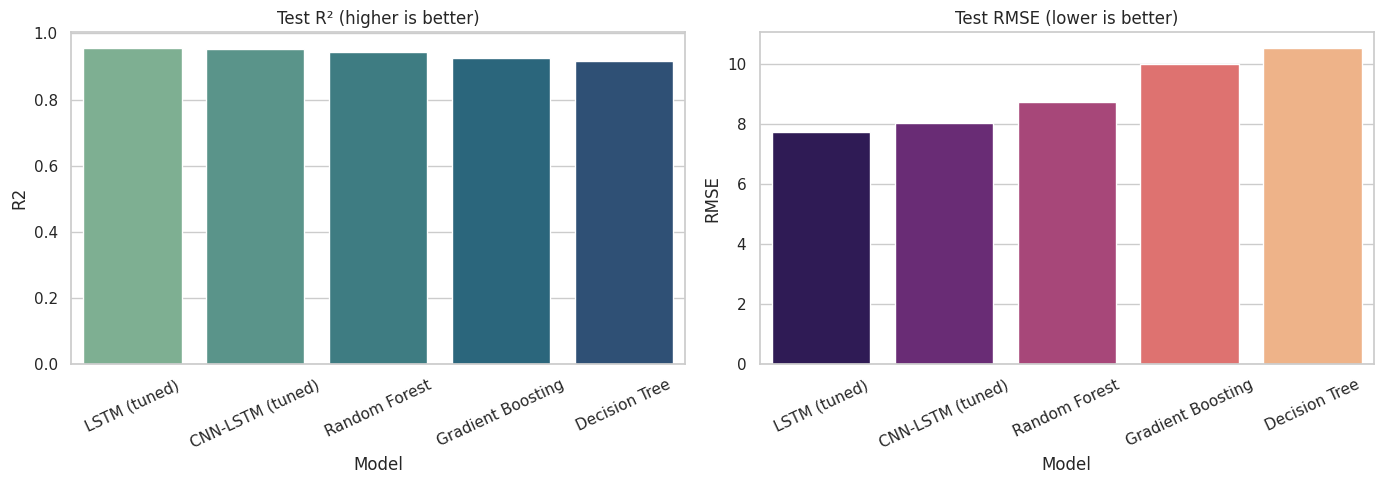

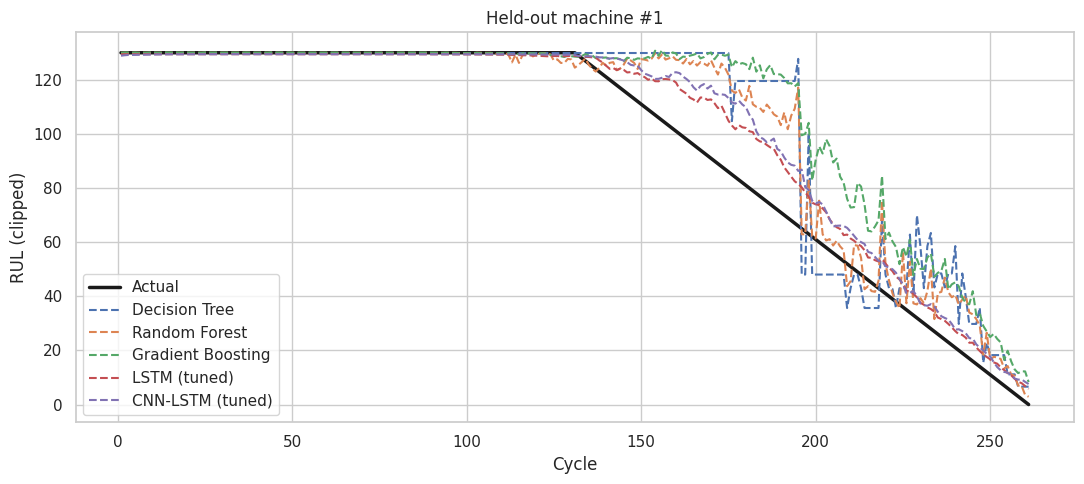

Total runtime: 13.1 min | files saved to ./outputs/


In [16]:
res = pd.DataFrame(results)[["Model", "R2", "R2_std", "RMSE", "RMSE_std", "MAE", "AsymScore"]]
res = res.sort_values("R2", ascending=False).reset_index(drop=True)
print(res.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=res, x="Model", y="R2", ax=ax[0], palette="crest"); ax[0].set_title("Test R² (higher is better)")
sns.barplot(data=res, x="Model", y="RMSE", ax=ax[1], palette="magma"); ax[1].set_title("Test RMSE (lower is better)")
for a_ in ax: a_.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

uid = test["unit_id"].iloc[0]; mk = (test["unit_id"] == uid).values
plt.figure(figsize=(11, 5)); plt.plot(test.loc[mk, "cycle"], y_te[mk], "k-", lw=2.5, label="Actual")
for n, p in preds.items(): plt.plot(test.loc[mk, "cycle"], p[mk], "--", label=n)
plt.xlabel("Cycle"); plt.ylabel("RUL (clipped)"); plt.title(f"Held-out machine #{uid}")
plt.legend(); plt.tight_layout(); plt.show()

res.to_csv("outputs/model_comparison.csv", index=False)
out = test[["unit_id", "cycle", TARGET]].reset_index(drop=True); out["RUL_clipped"] = y_te
for n, p in preds.items(): out["pred_" + n.replace(" ", "_").replace("(", "").replace(")", "")] = p
out.to_csv("outputs/test_predictions.csv", index=False)
model_cnn.save("outputs/cnn_lstm_final.keras")
print(f"Total runtime: {(time.time()-T0)/60:.1f} min | files saved to ./outputs/")

In [17]:

import joblib
from pathlib import Path
EXPORT = Path("outputs/models"); EXPORT.mkdir(parents=True, exist_ok=True)

def slug(name):
    return name.split(" (")[0].lower().replace("-", "_").replace(" ", "_")

model_entries = []
for name, m in TAB_MODELS.items():
    fname = slug(name) + ".joblib"
    joblib.dump(m, EXPORT / fname)
    model_entries.append({"name": name, "kind": "tabular", "files": [fname], "window": None})

for name, ms in FINAL_MODELS.items():
    window = best_cnn["window"] if "CNN" in name else best_lstm["window"]
    files = []
    for i, m in enumerate(ms):
        fn = f"{slug(name)}_seed{SEEDS[i]}.keras"
        m.save(EXPORT / fn); files.append(fn)
    model_entries.append({"name": name, "kind": "deep", "files": files, "window": int(window)})

config = {
    "format_version": 1,
    "sensor_cols": SENSOR_COLS,
    "key_sensors": KEY,
    "features": FEATURES,
    "rul_clip": RUL_CLIP,
    "dedupe": True,
    "median": {c: float(med[c]) for c in SENSOR_COLS},
    "lower": {c: float(lo[c]) for c in SENSOR_COLS},
    "upper": {c: float(hi[c]) for c in SENSOR_COLS},
    "scaler_mean": [float(x) for x in scaler.mean_],
    "scaler_scale": [float(x) for x in scaler.scale_],
    "models": model_entries,
    "sklearn_version": __import__("sklearn").__version__,
    "tensorflow_version": tf.__version__,
}
with open(EXPORT / "preprocessing.json", "w") as f:
    json.dump(config, f, indent=2)
print("Exported", len(model_entries), "model entries to outputs/models/")
for e in model_entries: print(" -", e["name"], e["kind"], e["files"])

Exported 5 model entries to outputs/models/
 - Decision Tree tabular ['decision_tree.joblib']
 - Random Forest tabular ['random_forest.joblib']
 - Gradient Boosting tabular ['gradient_boosting.joblib']
 - LSTM (tuned) deep ['lstm_seed42.keras', 'lstm_seed43.keras', 'lstm_seed44.keras']
 - CNN-LSTM (tuned) deep ['cnn_lstm_seed42.keras', 'cnn_lstm_seed43.keras', 'cnn_lstm_seed44.keras']


In [18]:
!zip -r outputs.zip outputs
from google.colab import files
files.download("outputs.zip")

updating: outputs/ (stored 0%)
updating: outputs/readme.txt (stored 0%)
  adding: outputs/best_params.json (deflated 51%)
  adding: outputs/cnn_lstm_final.keras (deflated 16%)
  adding: outputs/model_comparison.csv (deflated 37%)
  adding: outputs/models/ (stored 0%)
  adding: outputs/models/decision_tree.joblib (deflated 64%)
  adding: outputs/models/lstm_seed44.keras (deflated 12%)
  adding: outputs/models/gradient_boosting.joblib (deflated 50%)
  adding: outputs/models/cnn_lstm_seed43.keras (deflated 16%)
  adding: outputs/models/cnn_lstm_seed44.keras (deflated 16%)
  adding: outputs/models/cnn_lstm_seed42.keras (deflated 16%)
  adding: outputs/models/preprocessing.json (deflated 71%)
  adding: outputs/models/lstm_seed42.keras (deflated 12%)
  adding: outputs/models/random_forest.joblib (deflated 71%)
  adding: outputs/models/lstm_seed43.keras (deflated 12%)
  adding: outputs/test_predictions.csv (deflated 67%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Notes for the Dissertation
- Report the ranking from **your** run (Section 9), not from expectations.
- If the CNN-LSTM–LSTM gap is smaller than the seed standard deviation, say the models are statistically
  comparable rather than claiming superiority.
- `FAST = True` uses fewer trials and seeds than the full protocol. State which setting produced the reported numbers.
- The dataset is synthetic; generalisation to real plant data is not yet demonstrated.

[*] Initiating fine-tuned hyperparameter optimization for CNN-LSTM...

[+] Optimization Completed successfully!
Best Val RMSE: 5.8993
Optimized Parameters: {'window': 30, 'filters': 32, 'kernel_size': 3, 'lstm1_units': 64, 'lstm2_units': 32, 'dense_units': 32, 'dropout_rate': 0.10411689885916049, 'lr': 0.0009644206509183135, 'batch_size': 256}

[*] Training the optimized CNN-LSTM model on best parameters...
Epoch 1/40
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 11787.2080 - val_loss: 10038.0518 - learning_rate: 9.6442e-04
Epoch 2/40
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 6854.0605 - val_loss: 4364.1968 - learning_rate: 9.6442e-04
Epoch 3/40
106/106 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 2230.2168 - val_loss: 870.6673 - learning_rate: 9.6442e-04
Epoch 4/40
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 367.9744 - val_loss: 127.3340 - learning_rate: 9.6442e-04
Epoch 5/40
106/106 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 84.0600 - val_loss: 49.7812 - learning_rate: 

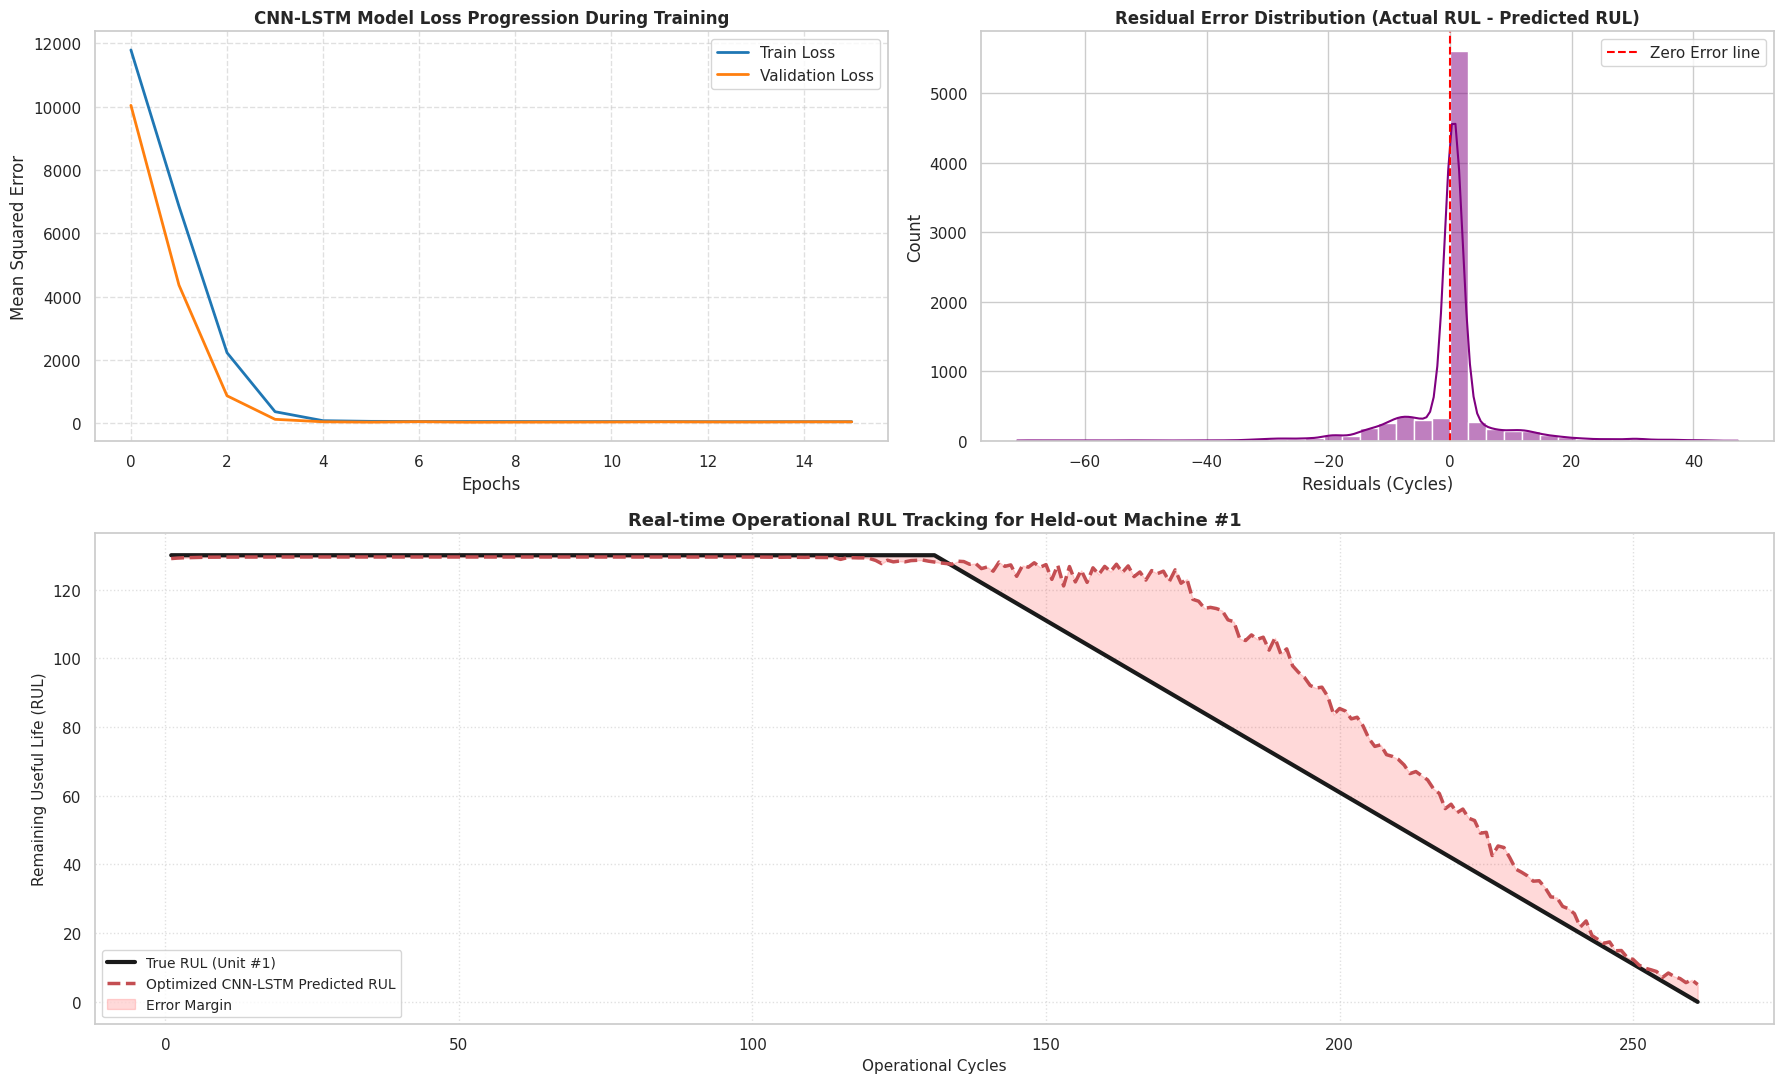

In [19]:
# =====================================================================
# ADVANCED CNN-LSTM HYPERPARAMETER TUNING & PERFORMANCE VISUALIZATION
# =====================================================================
%pip install -q optuna

import optuna
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import os
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import GroupShuffleSplit

# Ensure settings & globals exist if they are not defined
try:
    _ = train
    _ = test
except NameError:
    # Fallback initialization using the global settings if notebook state was lost
    matched_files = [f for f in os.listdir('.') if f.startswith('cnc_machining_centre_rul_dataset') and f.endswith('.csv')]
    if len(matched_files) > 0:
        data_file_path = matched_files[0]
    else:
        try:
            from google.colab import files
            print("[*] Dataset not found in current session. Please upload the dataset file:")
            uploaded = files.upload()
            data_file_path = list(uploaded.keys())[0]
        except Exception as e:
            print("[-] Automatic upload prompt failed. Defaulting file name.")
            data_file_path = "cnc_machining_centre_rul_dataset (2).csv"

    df = pd.read_csv(data_file_path).drop_duplicates().sort_values(["unit_id", "cycle"]).reset_index(drop=True)
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    tr_idx, te_idx = next(gss.split(df, groups=df["unit_id"]))
    train = df.iloc[tr_idx].copy(); test = df.iloc[te_idx].copy()

    # Cleaning
    SENSOR_COLS = [c for c in df.columns if c not in ["unit_id", "cycle", "timestamp", "shift", "machine_type", "RUL", "label_binary_30", "label_binary_15", "health_state", "failure_mode", "ambient_light_lux", "power_grid_voltage_V"]]
    med = train[SENSOR_COLS].median()
    q1, q3 = train[SENSOR_COLS].quantile(0.25), train[SENSOR_COLS].quantile(0.75)
    lo, hi = q1 - 3 * (q3 - q1), q3 + 3 * (q3 - q1)
    for p in (train, test):
        p[SENSOR_COLS] = p[SENSOR_COLS].fillna(med).clip(lower=lo, upper=hi, axis=1)

    # Engineering
    KEY = [c for c in ["spindle_vibration_x_mm_s", "spindle_vibration_y_mm_s", "spindle_vibration_z_mm_s",
                       "bearing_temperature_C", "motor_current_A", "spindle_torque_Nm", "tool_wear_mm",
                       "acoustic_emission_dB", "cutting_force_N", "power_consumption_kW"] if c in SENSOR_COLS]
    new_tr, new_te = {}, {}
    for c in KEY:
        new_tr[f"{c}_mean5"] = train.groupby("unit_id")[c].transform(lambda s: s.rolling(5, min_periods=1).mean())
        new_tr[f"{c}_std5"] = train.groupby("unit_id")[c].transform(lambda s: s.rolling(5, min_periods=2).std().fillna(0))
        new_tr[f"{c}_mean15"] = train.groupby("unit_id")[c].transform(lambda s: s.rolling(15, min_periods=1).mean())
        new_tr[f"{c}_diff1"] = train.groupby("unit_id")[c].diff().fillna(0)
        new_tr[f"{c}_ewm10"] = train.groupby("unit_id")[c].transform(lambda s: s.ewm(span=10, adjust=False).mean())
        new_te[f"{c}_mean5"] = test.groupby("unit_id")[c].transform(lambda s: s.rolling(5, min_periods=1).mean())
        new_te[f"{c}_std5"] = test.groupby("unit_id")[c].transform(lambda s: s.rolling(5, min_periods=2).std().fillna(0))
        new_te[f"{c}_mean15"] = test.groupby("unit_id")[c].transform(lambda s: s.rolling(15, min_periods=1).mean())
        new_te[f"{c}_diff1"] = test.groupby("unit_id")[c].diff().fillna(0)
        new_te[f"{c}_ewm10"] = test.groupby("unit_id")[c].transform(lambda s: s.ewm(span=10, adjust=False).mean())

    train = pd.concat([train, pd.DataFrame(new_tr, index=train.index)], axis=1)
    test = pd.concat([test, pd.DataFrame(new_te, index=test.index)], axis=1)
    FEATURES = SENSOR_COLS + [c for c in train.columns if c not in df.columns]
    from sklearn.preprocessing import StandardScaler
    scaler = StandardScaler().fit(train[FEATURES])
    train[FEATURES] = scaler.transform(train[FEATURES])
    test[FEATURES] = scaler.transform(test[FEATURES])

TUNE_EPOCHS = 15
FINAL_EPOCHS = 40
RUL_CLIP = 130

try:
    _ = make_sequences
except NameError:
    def make_sequences(part, window):
        X, y = [], []
        for _, g in part.groupby("unit_id", sort=False):
            F = g[FEATURES].values.astype(np.float32)
            r = g["RUL"].clip(upper=RUL_CLIP).values.astype(np.float32)
            Fp = np.vstack([np.zeros((window - 1, F.shape[1]), np.float32), F])
            for i in range(len(F)):
                X.append(Fp[i:i + window]); y.append(r[i])
        return np.stack(X), np.array(y, np.float32)

try:
    _ = inner_seq
except NameError:
    a, b = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=43).split(train, groups=train.unit_id))
    inner_tr, inner_va = train.iloc[a], train.iloc[b]
    _cache = {}
    def inner_seq(w):
        if w not in _cache:
            _cache[w] = (*make_sequences(inner_tr, w), *make_sequences(inner_va, w))
        return _cache[w]

try:
    _ = fit_seq
except NameError:
    def fit_seq(make, Xa, ya, Xb, yb, epochs, batch, seed):
        np.random.seed(seed); tf.random.set_seed(seed)
        m = make()
        m.fit(Xa, ya, validation_data=(Xb, yb), epochs=epochs, batch_size=batch, verbose=0,
              callbacks=[EarlyStopping("val_loss", patience=6, restore_best_weights=True),
                         ReduceLROnPlateau("val_loss", factor=0.5, patience=3, min_lr=1e-5)])
        return m

print("[*] Initiating fine-tuned hyperparameter optimization for CNN-LSTM...")

def build_advanced_cnn_lstm(w, nf, filters, kernel_size, lstm1_units, lstm2_units, dense_units, dropout_rate, lr):
    from tensorflow.keras import Sequential, layers
    model = Sequential([
        layers.Input((w, nf)),
        layers.Conv1D(filters=filters, kernel_size=kernel_size, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv1D(filters=filters // 2, kernel_size=kernel_size, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2, padding="same"),
        layers.LSTM(lstm1_units, return_sequences=True),
        layers.Dropout(dropout_rate),
        layers.LSTM(lstm2_units),
        layers.Dropout(dropout_rate),
        layers.Dense(dense_units, activation="relu"),
        layers.Dense(1)
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss="mse")
    return model

def obj_advanced_cnn(trial):
    w = trial.suggest_categorical("window", [20, 30])
    Xa, ya, Xb, yb = inner_seq(w)

    # Extended search space
    filters = trial.suggest_categorical("filters", [32, 64])
    kernel_size = trial.suggest_categorical("kernel_size", [3, 5])
    lstm1_units = trial.suggest_categorical("lstm1_units", [32, 64])
    lstm2_units = trial.suggest_categorical("lstm2_units", [16, 32])
    dense_units = trial.suggest_categorical("dense_units", [32])
    dropout_rate = trial.suggest_float("dropout_rate", 0.1, 0.3)
    lr = trial.suggest_float("lr", 3e-4, 1e-3, log=True)
    batch_size = trial.suggest_categorical("batch_size", [256])

    model = fit_seq(
        lambda: build_advanced_cnn_lstm(w, Xa.shape[2], filters, kernel_size, lstm1_units, lstm2_units, dense_units, dropout_rate, lr),
        Xa, ya, Xb, yb, epochs=TUNE_EPOCHS, batch=batch_size, seed=42
    )
    preds = model.predict(Xb, verbose=0).ravel()
    return float(np.sqrt(mean_squared_error(yb, preds)))

# Run localized optimization
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(obj_advanced_cnn, n_trials=4)
best_params = study.best_params
print("\n[+] Optimization Completed successfully!")
print(f"Best Val RMSE: {study.best_value:.4f}")
print("Optimized Parameters:", best_params)

# Re-training with optimized parameters
print("\n[*] Training the optimized CNN-LSTM model on best parameters...")
w_opt = best_params["window"]
Xa, ya, Xb, yb = inner_seq(w_opt)
Xte, yte = make_sequences(test, w_opt)

opt_model = build_advanced_cnn_lstm(
    w_opt, Xa.shape[2],
    best_params["filters"], best_params["kernel_size"],
    best_params["lstm1_units"], best_params["lstm2_units"],
    best_params["dense_units"], best_params["dropout_rate"],
    best_params["lr"]
)

history = opt_model.fit(
    Xa, ya, validation_data=(Xb, yb),
    epochs=FINAL_EPOCHS, batch_size=best_params["batch_size"],
    callbacks=[
        EarlyStopping("val_loss", patience=8, restore_best_weights=True),
        ReduceLROnPlateau("val_loss", factor=0.5, patience=4, min_lr=1e-6)
    ],
    verbose=1
)

# Predictions on test set
test_preds = opt_model.predict(Xte, verbose=0).ravel()
rmse = np.sqrt(mean_squared_error(yte, test_preds))
mae = mean_absolute_error(yte, test_preds)
r2 = r2_score(yte, test_preds)
print(f"\n[+] Evaluation Metrics on Held-out Test Set:\n  - RMSE: {rmse:.3f}\n  - MAE:  {mae:.3f}\n  - R2:   {r2:.3f}")

# =====================================================================
# PERFORMANCE VISUALIZATION DASHBOARD
# =====================================================================
fig = plt.figure(figsize=(18, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2])

# 1. Learning Curves
ax0 = fig.add_subplot(gs[0, 0])
ax0.plot(history.history['loss'], label='Train Loss', color='#1f77b4', lw=2)
ax0.plot(history.history['val_loss'], label='Validation Loss', color='#ff7f0e', lw=2)
ax0.set_title('CNN-LSTM Model Loss Progression During Training', fontsize=12, fontweight='bold')
ax0.set_xlabel('Epochs')
ax0.set_ylabel('Mean Squared Error')
ax0.legend()
ax0.grid(True, linestyle='--', alpha=0.6)

# 2. Predicted vs. True Residuals Plot
ax1 = fig.add_subplot(gs[0, 1])
residuals = yte - test_preds
sns.histplot(residuals, kde=True, color='purple', ax=ax1, bins=40, edgecolor='white')
ax1.axvline(x=0, color='red', linestyle='--', label='Zero Error line')
ax1.set_title('Residual Error Distribution (Actual RUL - Predicted RUL)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Residuals (Cycles)')
ax1.legend()

# 3. Comprehensive Predicted vs. Actual Progression Over Time
ax2 = fig.add_subplot(gs[1, :])
uid = test["unit_id"].iloc[0]
mk = (test["unit_id"].values == uid)
ax2.plot(test.loc[mk, "cycle"].values, yte[mk], "k-", lw=3.0, label=f"True RUL (Unit #{uid})")
ax2.plot(test.loc[mk, "cycle"].values, test_preds[mk], "r--", lw=2.5, label="Optimized CNN-LSTM Predicted RUL")
ax2.fill_between(test.loc[mk, "cycle"].values, yte[mk], test_preds[mk], color='red', alpha=0.15, label='Error Margin')
ax2.set_xlabel("Operational Cycles", fontsize=11)
ax2.set_ylabel("Remaining Useful Life (RUL)", fontsize=11)
ax2.set_title(f"Real-time Operational RUL Tracking for Held-out Machine #{uid}", fontsize=13, fontweight='bold')
ax2.legend(loc='lower left', fontsize=10)
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


In [20]:
!zip -r outputs.zip outputs
from google.colab import files
files.download("outputs.zip")

updating: outputs/ (stored 0%)
updating: outputs/readme.txt (stored 0%)
updating: outputs/best_params.json (deflated 51%)
updating: outputs/cnn_lstm_final.keras (deflated 16%)
updating: outputs/model_comparison.csv (deflated 37%)
updating: outputs/models/ (stored 0%)
updating: outputs/models/decision_tree.joblib (deflated 64%)
updating: outputs/models/lstm_seed44.keras (deflated 12%)
updating: outputs/models/gradient_boosting.joblib (deflated 50%)
updating: outputs/models/cnn_lstm_seed43.keras (deflated 16%)
updating: outputs/models/cnn_lstm_seed44.keras (deflated 16%)
updating: outputs/models/cnn_lstm_seed42.keras (deflated 16%)
updating: outputs/models/preprocessing.json (deflated 71%)
updating: outputs/models/lstm_seed42.keras (deflated 12%)
updating: outputs/models/random_forest.joblib (deflated 71%)
updating: outputs/models/lstm_seed43.keras (deflated 12%)
updating: outputs/test_predictions.csv (deflated 67%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>